# Liu et al. (2025) DARM: Panasonic 25°C → 0°C

This notebook runs the manifest-controlled experiment. Target Cycle 1 is unlabelled during adaptation; target SOC is used only for final evaluation.

Start with `RUN_MODE = "smoke"`. Switch to `"formal"` only after the manifest and GPU checks pass.

In [15]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [16]:
from pathlib import Path

REPO_URL = "https://github.com/zhangcastle/battery-soc-transfer-benchmark.git"
REPO_ROOT = Path("/content/battery-soc-transfer-benchmark")
DATA_ROOT = Path("/content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF")
OUTPUT_ROOT = Path("/content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c")
RUN_MODE = "smoke"  # "smoke" or "formal"
SEED = 42

assert RUN_MODE in {"smoke", "formal"}


In [17]:
import shutil
import subprocess
import sys

from google.colab import drive, userdata

drive.mount("/content/drive")

token = userdata.get("GITHUB_TOKEN")
assert token, "GITHUB_TOKEN is unavailable"

subprocess.run(
    ["gh", "auth", "login", "--hostname", "github.com", "--with-token"],
    input=token,
    text=True,
    check=True,
)
subprocess.run(["gh", "auth", "setup-git"], check=True)

# Remove a partial directory left by the failed clone.
if REPO_ROOT.exists() and not (REPO_ROOT / ".git").exists():
    shutil.rmtree(REPO_ROOT)

if (REPO_ROOT / ".git").exists():
    subprocess.run(
        ["git", "-C", str(REPO_ROOT), "pull", "--ff-only"],
        check=True,
    )
else:
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_ROOT)],
        check=True,
    )

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO_ROOT)],
    check=True,
)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print(f"Repository: {REPO_ROOT}")
print(f"Data:       {DATA_ROOT}")
print(f"Outputs:    {OUTPUT_ROOT}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repository: /content/battery-soc-transfer-benchmark
Data:       /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF
Outputs:    /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c


In [18]:
import torch

assert torch.cuda.is_available(), "Select a Colab GPU runtime before training."
gpu = torch.cuda.get_device_properties(0)
print(f"GPU: {gpu.name}")
print(f"VRAM: {gpu.total_memory / 2**30:.1f} GiB")
print("L4 memory is sufficient; formal-run duration is the main constraint.")


GPU: NVIDIA L4
VRAM: 22.0 GiB
L4 memory is sufficient; formal-run duration is the main constraint.


In [19]:
import subprocess
import sys

source_root = REPO_ROOT / "src"

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", str(REPO_ROOT)],
    check=True,
)

if str(source_root) not in sys.path:
    sys.path.insert(0, str(source_root))

import battery_benchmark

print(f"Package loaded from: {battery_benchmark.__file__}")

Package loaded from: /content/battery-soc-transfer-benchmark/src/battery_benchmark/__init__.py


In [20]:
import pandas as pd

from battery_benchmark.reproductions.liu_2025.protocol import load_experiment_manifest

MANIFEST = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
manifest = load_experiment_manifest(MANIFEST, DATA_ROOT, verify_hashes=True)
display(manifest[["record_id", "temperature_c", "role", "profile", "label_usage"]])
display(manifest.groupby(["role", "label_usage"]).size().rename("files"))
assert manifest.loc[manifest.role == "target_adapt", "label_usage"].tolist() == ["forbidden"]


,record_id,temperature_c,role,profile,label_usage
0,source_train_cycle_1,25,source_train,Cycle_1,train
1,source_train_cycle_2,25,source_train,Cycle_2,train
2,source_train_cycle_3,25,source_train,Cycle_3,train
3,source_train_cycle_4,25,source_train,Cycle_4,train
4,source_test_la92,25,source_test,LA92,evaluation_only
5,source_test_udds,25,source_test,UDDS,evaluation_only
6,source_test_us06,25,source_test,US06,evaluation_only
7,source_test_hwfet_a,25,source_test,HWFET,evaluation_only
8,source_test_hwfet_b,25,source_test,HWFET,evaluation_only
9,source_test_nn,25,source_test,NN,evaluation_only


,,files
role,label_usage,
source_test,evaluation_only,6
source_train,train,4
target_adapt,forbidden,1
target_test,evaluation_only,5


In [21]:
script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
run_output = OUTPUT_ROOT / RUN_MODE
command = [
    sys.executable,
    str(script),
    "--manifest", str(MANIFEST),
    "--data-root", str(DATA_ROOT),
    "--output", str(run_output),
    "--device", "cuda",
    "--seed", str(SEED),
]
if RUN_MODE == "smoke":
    command += ["--smoke", "--max-windows", "2048"]
else:
    command += ["--resume"]

print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)


/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/smoke --device cuda --seed 42 --smoke --max-windows 2048


KeyboardInterrupt: 

,method,profile,rmse_percent,mae_percent,n_windows
0,Source only,LA92,50.232517,45.033531,2048
1,Source only,UDDS,32.559784,27.581602,2048
2,Source only,US06,32.601974,27.879965,2048
3,Source only,HWFET,32.933773,28.018654,2048
4,Source only,NN,52.014286,47.218483,2048
5,DARM,LA92,35.585773,32.700218,2048
6,DARM,UDDS,31.355661,26.404902,2048
7,DARM,US06,33.404903,28.005754,2048
8,DARM,HWFET,32.578609,27.373188,2048
9,DARM,NN,36.281178,33.660297,2048


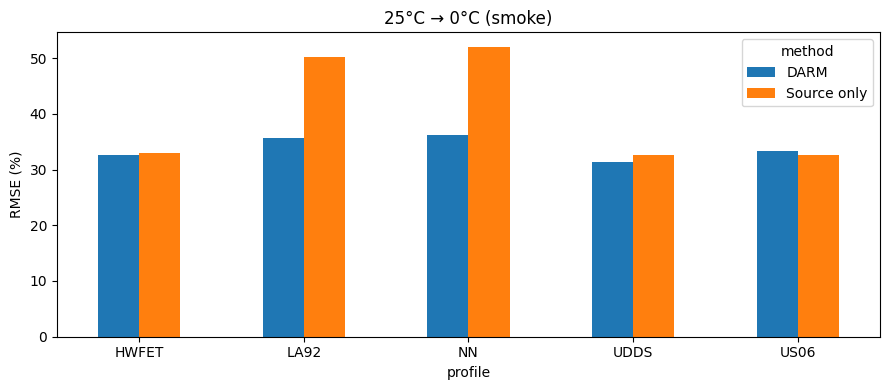

In [ ]:
import json
import matplotlib.pyplot as plt

result = json.loads((run_output / "results.json").read_text())
rows = []
for method, key in [("Source only", "target_source_only"), ("DARM", "target_darm")]:
    for profile, metrics in result[key].items():
        rows.append({"method": method, "profile": profile, **metrics})
metrics = pd.DataFrame(rows)
display(metrics)
metrics.pivot(index="profile", columns="method", values="rmse_percent").plot.bar(
    ylabel="RMSE (%)", rot=0, figsize=(9, 4)
)
plt.title(f"25°C → 0°C ({RUN_MODE})")
plt.tight_layout()
plt.show()


## Adaptation diagnostic

This optional run reuses the frozen formal source artifact, keeps the source BatchNorm state frozen, and evaluates selected adaptation epochs. Target labels are used only for post-epoch diagnosis, never for optimization, early stopping, or checkpoint selection.

In [ ]:
diagnostic_output = OUTPUT_ROOT / "diagnostic_bn_frozen"
source_artifact = OUTPUT_ROOT / "formal" / "source_artifact.pt"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

diagnostic_command = [
    sys.executable,
    str(script),
    "--manifest", str(MANIFEST),
    "--data-root", str(DATA_ROOT),
    "--output", str(diagnostic_output),
    "--source-artifact", str(source_artifact),
    "--device", "cuda",
    "--seed", str(SEED),
    "--diagnose-adaptation",
    "--resume",
]
print(" ".join(diagnostic_command))
subprocess.run(diagnostic_command, cwd=REPO_ROOT, check=True)

diagnostic = json.loads((diagnostic_output / "results.json").read_text())
rows = [
    {"epoch": 0, "profile": profile, **values}
    for profile, values in diagnostic["target_source_only"].items()
]
for checkpoint in diagnostic["adaptation_diagnostics"]:
    rows.extend(
        {"epoch": checkpoint["epoch"], "profile": profile, **values}
        for profile, values in checkpoint["target_test"].items()
    )
trajectory = pd.DataFrame(rows)
display(trajectory)
trajectory.groupby("epoch")["rmse_percent"].mean().plot(
    marker="o", ylabel="Mean profile RMSE (%)", grid=True, figsize=(8, 4)
)
plt.title("0°C adaptation trajectory")
plt.tight_layout()
plt.show()

display(pd.DataFrame(diagnostic["normalized_feature_ranges"]["target_adapt"]).T)


/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_bn_frozen --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal/source_artifact.pt --device cuda --seed 42 --diagnose-adaptation --resume


KeyError: 'target_test'

## Normalization / reconstruction A/B

These two diagnostic runs reuse the same formal source artifact. The first clips source-normalized inputs to `[0, 1]`; the second leaves normalization unchanged and sets the reconstruction weight to zero.

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
source_artifact = OUTPUT_ROOT / "formal" / "source_artifact.pt"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

experiments = {
    "clip_to_0_1": (OUTPUT_ROOT / "diagnostic_clip", ["--clip-normalized-inputs"]),
    "alpha_0": (OUTPUT_ROOT / "diagnostic_no_reconstruction", ["--alpha", "0"]),
}
ab_rows = []
for experiment, (experiment_output, extra_args) in experiments.items():
    command = [
        sys.executable,
        str(script),
        "--manifest", str(manifest_path),
        "--data-root", str(DATA_ROOT),
        "--output", str(experiment_output),
        "--source-artifact", str(source_artifact),
        "--device", "cuda",
        "--seed", str(SEED),
        "--diagnose-adaptation",
        "--resume",
        *extra_args,
    ]
    print(" ".join(command))
    subprocess.run(command, cwd=REPO_ROOT, check=True)
    result = json.loads((experiment_output / "results.json").read_text())
    ab_rows.extend(
        {"experiment": experiment, "epoch": 0, "profile": profile, **metrics}
        for profile, metrics in result["target_source_only"].items()
    )
    for checkpoint in result["adaptation_diagnostics"]:
        ab_rows.extend(
            {
                "experiment": experiment,
                "epoch": checkpoint["epoch"],
                "profile": profile,
                **metrics,
            }
            for profile, metrics in checkpoint["target_test"].items()
        )

ab_trajectory = pd.DataFrame(ab_rows)
ab_summary = (
    ab_trajectory.groupby(["experiment", "epoch"], as_index=False)["rmse_percent"]
    .mean()
    .rename(columns={"rmse_percent": "mean_profile_rmse_percent"})
)
display(ab_summary)
ab_summary.pivot(index="epoch", columns="experiment", values="mean_profile_rmse_percent").plot(
    marker="o", ylabel="Mean profile RMSE (%)", grid=True, figsize=(8, 4)
)
plt.title("0°C adaptation A/B")
plt.tight_layout()
plt.show()


## Alignment loss isolation

These runs disable reconstruction and isolate adversarial alignment from MK-MMD alignment.

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
source_artifact = OUTPUT_ROOT / "formal" / "source_artifact.pt"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

loss_experiments = {
    "adversarial_only": (
        OUTPUT_ROOT / "diagnostic_adversarial_only",
        ["--adversarial-weight", "1", "--alpha", "0", "--beta", "0"],
    ),
    "mmd_only": (
        OUTPUT_ROOT / "diagnostic_mmd_only",
        ["--adversarial-weight", "0", "--alpha", "0", "--beta", "1"],
    ),
}
loss_rows = []
for experiment, (experiment_output, weights) in loss_experiments.items():
    command = [
        sys.executable,
        str(script),
        "--manifest", str(manifest_path),
        "--data-root", str(DATA_ROOT),
        "--output", str(experiment_output),
        "--source-artifact", str(source_artifact),
        "--device", "cuda",
        "--seed", str(SEED),
        "--diagnose-adaptation",
        "--resume",
        *weights,
    ]
    print(" ".join(command))
    subprocess.run(command, cwd=REPO_ROOT, check=True)
    result = json.loads((experiment_output / "results.json").read_text())
    loss_rows.extend(
        {"experiment": experiment, "epoch": 0, "profile": profile, **metrics}
        for profile, metrics in result["target_source_only"].items()
    )
    for checkpoint in result["adaptation_diagnostics"]:
        loss_rows.extend(
            {
                "experiment": experiment,
                "epoch": checkpoint["epoch"],
                "profile": profile,
                **metrics,
            }
            for profile, metrics in checkpoint["target_test"].items()
        )

loss_trajectory = pd.DataFrame(loss_rows)
loss_summary = (
    loss_trajectory.groupby(["experiment", "epoch"], as_index=False)["rmse_percent"]
    .mean()
    .rename(columns={"rmse_percent": "mean_profile_rmse_percent"})
)
display(loss_summary)
loss_summary.pivot(index="epoch", columns="experiment", values="mean_profile_rmse_percent").plot(
    marker="o", ylabel="Mean profile RMSE (%)", grid=True, figsize=(8, 4)
)
plt.title("0°C alignment-loss isolation")
plt.tight_layout()
plt.show()


## Target Cycle 1 normalization diagnostic

The paper states that measurements are min-max normalized to `[0, 1]` but does not identify the fitting scope. This diagnostic fits a separate target scaler using only unlabeled target Cycle 1; no target SOC or target-test statistics are used.

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
source_artifact = OUTPUT_ROOT / "formal" / "source_artifact.pt"
target_normalized_output = OUTPUT_ROOT / "diagnostic_target_normalized"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

command = [
    sys.executable,
    str(script),
    "--manifest", str(manifest_path),
    "--data-root", str(DATA_ROOT),
    "--output", str(target_normalized_output),
    "--source-artifact", str(source_artifact),
    "--target-normalization", "target_adapt",
    "--device", "cuda",
    "--seed", str(SEED),
    "--diagnose-adaptation",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

target_normalized = json.loads((target_normalized_output / "results.json").read_text())
normalization_rows = [
    {"epoch": 0, "profile": profile, **metrics}
    for profile, metrics in target_normalized["target_source_only"].items()
]
for checkpoint in target_normalized["adaptation_diagnostics"]:
    normalization_rows.extend(
        {"epoch": checkpoint["epoch"], "profile": profile, **metrics}
        for profile, metrics in checkpoint["target_test"].items()
    )

normalization_trajectory = pd.DataFrame(normalization_rows)
normalization_summary = (
    normalization_trajectory.groupby("epoch", as_index=False)["rmse_percent"]
    .mean()
    .rename(columns={"rmse_percent": "mean_profile_rmse_percent"})
)
display(normalization_summary)
normalization_summary.plot(
    x="epoch", y="mean_profile_rmse_percent", marker="o", grid=True, figsize=(8, 4)
)
plt.ylabel("Mean profile RMSE (%)")
plt.title("0°C target-normalized adaptation")
plt.tight_layout()
plt.show()
display(pd.DataFrame(target_normalized["normalized_feature_ranges"]["target_adapt"]).T)


## Target-domain normalization diagnostic

This transductive diagnostic fits one min-max scaler on all 0°C input covariates. It never reads target SOC labels, but it does use target-test feature ranges and is therefore not the leakage-free default protocol.

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
source_artifact = OUTPUT_ROOT / "formal" / "source_artifact.pt"
target_domain_output = OUTPUT_ROOT / "diagnostic_target_domain_normalized"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

command = [
    sys.executable,
    str(script),
    "--manifest", str(manifest_path),
    "--data-root", str(DATA_ROOT),
    "--output", str(target_domain_output),
    "--source-artifact", str(source_artifact),
    "--target-normalization", "target_domain",
    "--device", "cuda",
    "--seed", str(SEED),
    "--diagnose-adaptation",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

target_domain = json.loads((target_domain_output / "results.json").read_text())
domain_rows = [
    {"epoch": 0, "profile": profile, **metrics}
    for profile, metrics in target_domain["target_source_only"].items()
]
for checkpoint in target_domain["adaptation_diagnostics"]:
    domain_rows.extend(
        {"epoch": checkpoint["epoch"], "profile": profile, **metrics}
        for profile, metrics in checkpoint["target_test"].items()
    )

domain_trajectory = pd.DataFrame(domain_rows)
domain_summary = (
    domain_trajectory.groupby("epoch", as_index=False)["rmse_percent"]
    .mean()
    .rename(columns={"rmse_percent": "mean_profile_rmse_percent"})
)
display(domain_summary)
domain_summary.plot(
    x="epoch", y="mean_profile_rmse_percent", marker="o", grid=True, figsize=(8, 4)
)
plt.ylabel("Mean profile RMSE (%)")
plt.title("0°C target-domain-normalized adaptation")
plt.tight_layout()
plt.show()
display(pd.DataFrame(target_domain["normalized_feature_ranges"]["target_adapt"]).T)


## Full rerun with the paper feature order

The paper defines each input as `[current, voltage, temperature]`. This full run trains a separate source artifact with that order and then performs the 25°C → 0°C adaptation. It never overwrites the original formal run.

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
paper_order_output = OUTPUT_ROOT / "formal_paper_ivt"
command = [
    sys.executable,
    str(script),
    "--manifest", str(manifest_path),
    "--data-root", str(DATA_ROOT),
    "--output", str(paper_order_output),
    "--feature-order", "paper_ivt",
    "--device", "cuda",
    "--seed", str(SEED),
    "--diagnose-adaptation",
    "--resume",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

paper_order = json.loads((paper_order_output / "results.json").read_text())
source_rows = [
    {"profile": profile, **metrics}
    for profile, metrics in paper_order["source_test"].items()
]
display(pd.DataFrame(source_rows))

target_rows = []
for method, key in (("Source only", "target_source_only"), ("DARM", "target_darm")):
    target_rows.extend(
        {"method": method, "profile": profile, **metrics}
        for profile, metrics in paper_order[key].items()
    )
paper_order_metrics = pd.DataFrame(target_rows)
display(paper_order_metrics)
paper_order_metrics.pivot(
    index="profile", columns="method", values="rmse_percent"
).plot.bar(ylabel="RMSE (%)", rot=0, figsize=(9, 4))
plt.title("25°C → 0°C with paper feature order")
plt.tight_layout()
plt.show()


## Source checkpoint comparison

This diagnostic compares the paper-order source artifact, best training-loss checkpoint, and last checkpoint without retraining or adapting.

In [ ]:
import json
import subprocess
import sys

import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
paper_order_output = OUTPUT_ROOT / "formal_paper_ivt"
source_artifact = paper_order_output / "source_artifact.pt"
comparison_output = OUTPUT_ROOT / "diagnostic_source_checkpoints"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

command = [
    sys.executable,
    str(script),
    "--manifest", str(manifest_path),
    "--data-root", str(DATA_ROOT),
    "--output", str(comparison_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--compare-source-checkpoints",
    "--device", "cuda",
    "--seed", str(SEED),
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

comparison = json.loads(
    (comparison_output / "source_checkpoint_comparison.json").read_text()
)
checkpoint_rows = []
for checkpoint_name, checkpoint in comparison["checkpoints"].items():
    for split in ("source_test", "target_source_only"):
        checkpoint_rows.extend(
            {
                "checkpoint": checkpoint_name,
                "split": split,
                "profile": profile,
                **metrics,
            }
            for profile, metrics in checkpoint[split].items()
        )

checkpoint_metrics = pd.DataFrame(checkpoint_rows)
display(checkpoint_metrics)
checkpoint_summary = (
    checkpoint_metrics.groupby(["checkpoint", "split"], as_index=False)["rmse_percent"]
    .mean()
    .rename(columns={"rmse_percent": "mean_profile_rmse_percent"})
)
display(checkpoint_summary)


## SOC-label and source-scaler audit

This diagnostic compares the current per-file Ah SOC labels with 2.75 Ah and 2.9 Ah capacity references, and reports source-scaler range violations. It does not train or adapt a model.

In [ ]:
import json
import subprocess
import sys

import pandas as pd

script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
paper_order_output = OUTPUT_ROOT / "formal_paper_ivt"
source_artifact = paper_order_output / "source_artifact.pt"
audit_output = OUTPUT_ROOT / "diagnostic_preprocessing_audit"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

command = [
    sys.executable,
    str(script),
    "--manifest", str(manifest_path),
    "--data-root", str(DATA_ROOT),
    "--output", str(audit_output),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--audit-preprocessing",
    "--device", "cuda",
]
print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)

audit = json.loads((audit_output / "preprocessing_audit.json").read_text())
label_comparison = pd.DataFrame(audit["label_formula_comparison"])
display(label_comparison[label_comparison.role.isin(["source_train", "source_test"])])

range_rows = []
for profile, features in audit["normalized_feature_ranges"]["source_test"].items():
    range_rows.extend(
        {"profile": profile, "feature": feature, **values}
        for feature, values in features.items()
    )
source_test_ranges = pd.DataFrame(range_rows)
display(source_test_ranges)
display(
    source_test_ranges.pivot(
        index="profile", columns="feature", values="outside_0_1_fraction"
    )
)


/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_preprocessing_audit --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_ivt/source_artifact.pt --feature-order paper_ivt --audit-preprocessing --device cuda


,role,profile,record_id,soc_denominator_ah,delivered_ah,soc_end_per_file_percent,soc_end_2_75ah_percent,mae_per_file_vs_2_75ah_percent,soc_end_2_9ah_percent,mae_per_file_vs_2_9ah_percent
0,source_train,Cycle_1,source_train_cycle_1,2.69557,2.69557,0.0,1.979273,0.943416,7.049310,3.360039
1,source_train,Cycle_2,source_train_cycle_2,2.71140,2.71132,0.0,1.406545,0.714614,6.506207,3.300289
2,source_train,Cycle_3,source_train_cycle_3,2.53031,2.53027,0.0,7.990182,4.087937,12.749310,6.522343
3,source_train,Cycle_4,source_train_cycle_4,2.79817,2.79817,0.0,-1.751636,0.886394,3.511379,1.776891
4,source_test,LA92,source_test_la92,2.58703,2.58703,0.0,5.926182,2.951382,10.792069,5.374712
5,source_test,UDDS,source_test_udds,2.70149,2.70149,0.0,1.764000,0.869631,6.845172,3.374590
6,source_test,US06,source_test_us06,2.58596,2.58596,0.0,5.965091,3.068674,10.828966,5.570839
7,source_test,HWFET,source_test_hwfet_a,2.70808,2.70808,0.0,1.524364,0.761568,6.617931,3.306299
8,source_test,HWFET,source_test_hwfet_b,2.70304,2.70304,0.0,1.707636,0.853788,6.791724,3.395741
9,source_test,NN,source_test_nn,2.54962,2.54962,0.0,7.286545,3.643935,12.082069,6.042133


,profile,feature,min,max,outside_0_1_fraction
0,LA92,current,0.310788,0.970648,0.000000
1,LA92,voltage,0.048330,0.997320,0.000000
2,LA92,temperature,0.466945,0.748431,0.000000
3,UDDS,current,0.395646,0.788087,0.000000
4,UDDS,voltage,0.035982,0.996521,0.000000
5,UDDS,temperature,0.465585,0.645083,0.000000
6,US06,current,-0.032440,0.903944,0.000209
7,US06,voltage,0.069078,0.996899,0.000000
8,US06,temperature,0.464225,1.333159,0.282159
9,HWFET,current,0.456396,0.830556,0.000000


feature,current,temperature,voltage
profile,,,
HWFET,0.000000,0.000000,0.000066
LA92,0.000000,0.000000,0.000000
NN,0.000000,0.000000,0.000000
UDDS,0.000000,0.000000,0.000000
US06,0.000209,0.282159,0.000000


In [ ]:
# Run the BN/adversarial update-semantics diagnostic suite on Colab L4.
import hashlib
import json
import os
import shutil
import subprocess
import sys
from getpass import getpass
from pathlib import Path

import pandas as pd
import torch
from google.colab import drive, userdata

drive.mount("/content/drive")

repo_root = Path("/content/battery-soc-transfer-benchmark")
repo_url = "https://github.com/zhangcastle/battery-soc-transfer-benchmark.git"
drive_root = Path("/content/drive/MyDrive/battery_soc_benchmark")
data_root = drive_root / "data/raw/Panasonic_18650PF"
liu_root = drive_root / "outputs/liu_2025/25c_to_0c"
suite_root = liu_root / "diagnostic_update_semantics_20260728"
source_artifact = liu_root / "formal_paper_ivt/source_artifact.pt"
bundle = suite_root / "liu_2025_update_semantics_code.tar.gz"
expected_bundle_sha256 = "70e300c211f45a8a48ae7af75a954e9d0fd30cd005d9be5007b941a0463639e3"

assert torch.cuda.is_available(), "A CUDA runtime is required"
gpu_name = torch.cuda.get_device_name(0)
assert "L4" in gpu_name, f"Expected an L4 runtime, got: {gpu_name}"
assert data_root.is_dir(), f"Missing data root: {data_root}"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
assert bundle.is_file(), f"Missing diagnostic code bundle: {bundle}"
assert hashlib.sha256(bundle.read_bytes()).hexdigest() == expected_bundle_sha256
print(f"GPU: {gpu_name}")

token = os.environ.get("GITHUB_TOKEN")
if not token:
    try:
        token = userdata.get("GITHUB_TOKEN")
    except Exception:
        token = None
if not token:
    token = getpass("GitHub token: ")
assert token, "GITHUB_TOKEN is unavailable"
subprocess.run(
    ["gh", "auth", "login", "--hostname", "github.com", "--with-token"],
    input=token,
    text=True,
    check=True,
)
subprocess.run(["gh", "auth", "setup-git"], check=True)
if repo_root.exists():
    subprocess.run(["git", "-C", str(repo_root), "pull", "--ff-only", "origin", "main"], check=True)
else:
    subprocess.run(["git", "clone", repo_url, str(repo_root)], check=True)
subprocess.run(["tar", "-xzf", str(bundle), "-C", str(repo_root)], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(repo_root)], check=True)

subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/reproductions/liu_2025/test_darm.py",
        "tests/reproductions/liu_2025/test_source_artifact.py",
        "tests/reproductions/liu_2025/test_run_reproduction.py",
        "-q",
    ],
    cwd=repo_root,
    check=True,
)

script = repo_root / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest = repo_root / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
common = [
    sys.executable,
    str(script),
    "--manifest", str(manifest),
    "--data-root", str(data_root),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--seed", "42",
    "--device", "cuda",
]
experiments = [
    (
        "bn_forward_audit",
        ["--audit-target-bn-forward"],
        "target_bn_forward_audit.json",
    ),
    (
        "adversarial_grl_legacy",
        ["--transfer-epochs", "1", "--patience", "0", "--adversarial-weight", "1", "--alpha", "0", "--beta", "0", "--target-bn-mode", "legacy", "--adversarial-update", "grl_joint"],
        "results.json",
    ),
    (
        "adversarial_grl_frozen_stats",
        ["--transfer-epochs", "1", "--patience", "0", "--adversarial-weight", "1", "--alpha", "0", "--beta", "0", "--target-bn-mode", "frozen_stats", "--adversarial-update", "grl_joint"],
        "results.json",
    ),
    (
        "adversarial_alternating_frozen_stats",
        ["--transfer-epochs", "1", "--patience", "0", "--adversarial-weight", "1", "--alpha", "0", "--beta", "0", "--target-bn-mode", "frozen_stats", "--adversarial-update", "alternating_flipped"],
        "results.json",
    ),
    (
        "adversarial_eq12_frozen_stats",
        ["--transfer-epochs", "1", "--patience", "0", "--adversarial-weight", "1", "--alpha", "0", "--beta", "0", "--target-bn-mode", "frozen_stats", "--adversarial-update", "eq12_joint"],
        "results.json",
    ),
    (
        "mmd_legacy",
        ["--transfer-epochs", "1", "--patience", "0", "--adversarial-weight", "0", "--alpha", "0", "--beta", "1", "--target-bn-mode", "legacy", "--adversarial-update", "grl_joint"],
        "results.json",
    ),
    (
        "mmd_frozen_stats",
        ["--transfer-epochs", "1", "--patience", "0", "--adversarial-weight", "0", "--alpha", "0", "--beta", "1", "--target-bn-mode", "frozen_stats", "--adversarial-update", "grl_joint"],
        "results.json",
    ),
]

suite_root.mkdir(parents=True, exist_ok=True)
for name, arguments, completion_file in experiments:
    output = suite_root / name
    if (output / completion_file).is_file():
        print(f"Skipping completed experiment: {name}")
        continue
    output.mkdir(parents=True, exist_ok=True)
    command = [*common, "--output", str(output), *arguments]
    print(f"\nRunning: {name}\n{' '.join(command)}")
    subprocess.run(command, cwd=repo_root, check=True)

summary_rows = []
for name, _, completion_file in experiments:
    result = json.loads((suite_root / name / completion_file).read_text())
    if completion_file == "target_bn_forward_audit.json":
        summary_rows.append(
            {
                "experiment": name,
                "mean_rmse_percent": sum(row["rmse_after_legacy_bn_forward"] for row in result["profiles"]) / len(result["profiles"]),
            }
        )
    else:
        training = result["target_training"]
        summary_rows.append(
            {
                "experiment": name,
                "mean_rmse_percent": training["mean_profile_rmse_percent"],
                "domain_accuracy": training["overall_domain_accuracy"],
                "p_source_given_target": training["mean_p_source_given_target"],
                "adversarial_gradient_l2": training["gradient_l2"]["adversarial"],
                "mmd_gradient_l2": training["gradient_l2"]["mmd"],
            }
        )
display(pd.DataFrame(summary_rows))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA L4

Running: bn_forward_audit
/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_ivt/source_artifact.pt --feature-order paper_ivt --seed 42 --device cuda --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_update_semantics_20260728/bn_forward_audit --audit-target-bn-forward

Running: adversarial_grl_legacy
/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/mani

,experiment,mean_rmse_percent,domain_accuracy,p_source_given_target,adversarial_gradient_l2,mmd_gradient_l2
0,bn_forward_audit,15.108423,NaN,NaN,NaN,NaN
1,adversarial_grl_legacy,15.069151,0.522616,0.506180,0.072820,0.000000
2,adversarial_grl_frozen_stats,7.912967,0.520910,0.529624,0.499420,0.000000
3,adversarial_alternating_frozen_stats,7.721993,0.515745,0.530219,0.891612,0.000000
4,adversarial_eq12_frozen_stats,13.783906,0.759283,0.467151,0.499420,0.000000
5,mmd_legacy,14.710135,0.511654,0.525209,0.000000,0.351380
6,mmd_frozen_stats,8.117056,0.477603,0.530391,0.000000,8.270257


## Frozen-BN full-loss 10-epoch diagnostic

This short run keeps the paper loss weights and uses `frozen_stats + grl_joint`. Target SOC labels are used only for post-epoch diagnostic evaluation, never for optimization or checkpoint selection.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_ivt/source_artifact.pt --feature-order paper_ivt --seed 42 --device cuda --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_frozen_stats_grl_full_loss_10ep --transfer-epochs 10 --patience 0 --adversarial-weight 1 --alpha 10 --beta 1 --target-bn-mode frozen_stats --adversarial-update grl_joint --resume


,epoch,mean_rmse_percent,total_loss,adversarial_loss,reconstruction_loss,mmd_loss,domain_accuracy,p_source_given_target,total_gradient_l2,target_feature_rms_drift,bn_mean_drift,bn_var_drift,bn_batches_drift
0,1,8.462688,26.770454,0.667242,2.582644,0.276770,0.623956,0.506019,82.965227,0.251959,0.0,0.0,0
1,2,7.722036,24.649266,0.612262,2.378578,0.251225,0.708402,0.465382,77.024532,0.268938,0.0,0.0,0
2,3,7.441435,22.868359,0.566848,2.206602,0.235490,0.749832,0.427482,92.009457,0.344741,0.0,0.0,0
3,4,7.464361,21.322459,0.522484,2.058255,0.217422,0.772709,0.390741,81.745340,0.345169,0.0,0.0,0
4,5,6.743344,19.885252,0.472124,1.920509,0.208038,0.804655,0.354279,37.101257,0.406253,0.0,0.0,0
5,6,7.400295,18.501803,0.418906,1.787838,0.204521,0.844159,0.319102,55.661541,0.428267,0.0,0.0,0
6,7,7.216065,17.252184,0.370504,1.668418,0.197503,0.869863,0.287587,49.549054,0.459597,0.0,0.0,0
7,8,7.227601,16.103228,0.333362,1.557669,0.193173,0.878699,0.257506,23.931230,0.468932,0.0,0.0,0
8,9,7.281037,15.023433,0.321935,1.451871,0.182793,0.877596,0.239197,30.999268,0.506942,0.0,0.0,0
9,10,7.240765,14.032507,0.317884,1.353539,0.179228,0.871456,0.230155,55.594200,0.531779,0.0,0.0,0


,epoch,profile,rmse_percent,mae_percent,n_windows
0,1,LA92,6.094450,4.426822,15368
1,1,UDDS,6.434844,5.129154,12831
2,1,US06,11.848049,10.660053,3635
3,1,HWFET,11.629197,10.826933,5961
4,1,NN,6.306900,4.429025,13439
5,2,LA92,5.471778,3.859115,15368
6,2,UDDS,5.817927,4.454423,12831
7,2,US06,11.057565,9.844778,3635
8,2,HWFET,10.515580,9.681123,5961
9,2,NN,5.747328,3.937466,13439


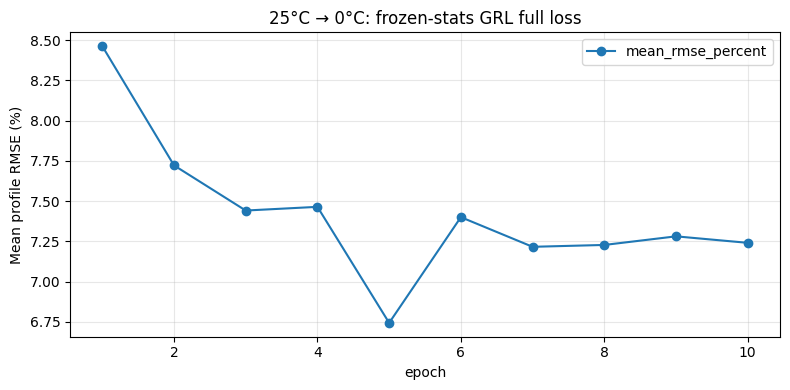

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

diagnostic_output = OUTPUT_ROOT / "diagnostic_frozen_stats_grl_full_loss_10ep"
source_artifact = OUTPUT_ROOT / "formal_paper_ivt/source_artifact.pt"
script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
diagnostic_output.mkdir(parents=True, exist_ok=True)
if not (diagnostic_output / "results.json").is_file():
    command = [
        sys.executable,
        str(script),
        "--manifest", str(manifest_path),
        "--data-root", str(DATA_ROOT),
        "--source-artifact", str(source_artifact),
        "--feature-order", "paper_ivt",
        "--seed", "42",
        "--device", "cuda",
        "--output", str(diagnostic_output),
        "--transfer-epochs", "10",
        "--patience", "0",
        "--adversarial-weight", "1",
        "--alpha", "10",
        "--beta", "1",
        "--target-bn-mode", "frozen_stats",
        "--adversarial-update", "grl_joint",
        "--resume",
    ]
    print(" ".join(command))
    subprocess.run(command, cwd=REPO_ROOT, check=True)
else:
    print(f"Using completed result: {diagnostic_output}")

result = json.loads((diagnostic_output / "results.json").read_text())
diagnostics = result["adaptation_diagnostics"]
assert result["target_bn_mode"] == "frozen_stats"
assert result["adversarial_update"] == "grl_joint"

epoch_rows = []
profile_rows = []
for record in diagnostics:
    training = record["training"]
    bn_drift = training["target_bn_running_stat_drift"]
    epoch_rows.append(
        {
            "epoch": record["epoch"],
            "mean_rmse_percent": training["mean_profile_rmse_percent"],
            "total_loss": training["total"],
            "adversarial_loss": training["adversarial"],
            "reconstruction_loss": training["reconstruction"],
            "mmd_loss": training["mmd"],
            "domain_accuracy": training["overall_domain_accuracy"],
            "p_source_given_target": training["mean_p_source_given_target"],
            "total_gradient_l2": training["gradient_l2"]["total"],
            "target_feature_rms_drift": training["target_feature_rms_drift"],
            "bn_mean_drift": bn_drift["max_running_mean_abs_change"],
            "bn_var_drift": bn_drift["max_running_var_abs_change"],
            "bn_batches_drift": bn_drift["max_num_batches_tracked_change"],
        }
    )
    if record["epoch"] in {1, 2, 5, 10}:
        for profile, metrics in training["target_test"].items():
            profile_rows.append({"epoch": record["epoch"], "profile": profile, **metrics})

epochs = pd.DataFrame(epoch_rows)
profiles = pd.DataFrame(profile_rows)
display(epochs)
display(profiles)
assert not epochs[["bn_mean_drift", "bn_var_drift", "bn_batches_drift"]].to_numpy().any()
epochs.plot(x="epoch", y="mean_rmse_percent", marker="o", ylabel="Mean profile RMSE (%)", figsize=(8, 4))
plt.title("25°C → 0°C: frozen-stats GRL full loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Full-loss component/update ablation

These two ten-epoch runs isolate the contribution of GRL and compare it with the alternating flipped-label update. They reuse the same source checkpoint, seed, data order, loss weights, and frozen target BN statistics. Target SOC remains diagnostic-only.


Running: reconstruction_mmd
/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_ivt/source_artifact.pt --feature-order paper_ivt --seed 42 --device cuda --transfer-epochs 10 --patience 0 --alpha 10 --beta 1 --target-bn-mode frozen_stats --resume --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_frozen_stats_reconstruction_mmd_10ep --adversarial-weight 0 --adversarial-update grl_joint

Running: alternating_flipped
/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_t

,experiment,epoch,mean_rmse_percent,domain_accuracy,p_source_given_target,adversarial_gradient_l2,reconstruction_gradient_l2,mmd_gradient_l2,target_feature_rms_drift,bn_mean_drift,bn_var_drift,bn_batches_drift
0,grl_joint,1,8.462688,0.623956,0.506019,0.499420,76.229216,8.270257,0.251959,0.0,0.0,0
1,grl_joint,2,7.722036,0.708402,0.465382,2.257898,88.775526,13.556035,0.268938,0.0,0.0,0
4,grl_joint,5,6.743344,0.804655,0.354279,8.514644,32.051673,11.605967,0.406253,0.0,0.0,0
9,grl_joint,10,7.240765,0.871456,0.230155,1.928682,47.899911,7.899761,0.531779,0.0,0.0,0
10,reconstruction_mmd,1,8.391565,0.441598,0.536356,0.000000,76.229216,8.270257,0.204823,0.0,0.0,0
11,reconstruction_mmd,2,8.286125,0.438415,0.534655,0.000000,53.042201,13.076584,0.275882,0.0,0.0,0
14,reconstruction_mmd,5,7.335782,0.440005,0.534287,0.000000,32.834618,12.045415,0.378920,0.0,0.0,0
19,reconstruction_mmd,10,6.913695,0.441983,0.535050,0.000000,64.895228,7.998296,0.453634,0.0,0.0,0
20,alternating_flipped,1,8.076135,0.625332,0.506642,0.891612,76.229216,8.270257,0.212418,0.0,0.0,0
21,alternating_flipped,2,7.569222,0.706263,0.469620,4.041168,382.001206,11.976403,0.319490,0.0,0.0,0


,experiment,profile,rmse_percent,mae_percent,n_windows
0,grl_joint,LA92,5.126106,3.591075,15368
1,grl_joint,UDDS,5.941535,4.618181,12831
2,grl_joint,US06,9.979188,8.709743,3635
3,grl_joint,HWFET,9.777336,8.803091,5961
4,grl_joint,NN,5.379658,3.693139,13439
5,reconstruction_mmd,LA92,4.905757,3.435701,15368
6,reconstruction_mmd,UDDS,5.704940,4.468042,12831
7,reconstruction_mmd,US06,9.615158,8.310474,3635
8,reconstruction_mmd,HWFET,9.208977,8.304117,5961
9,reconstruction_mmd,NN,5.133642,3.500181,13439


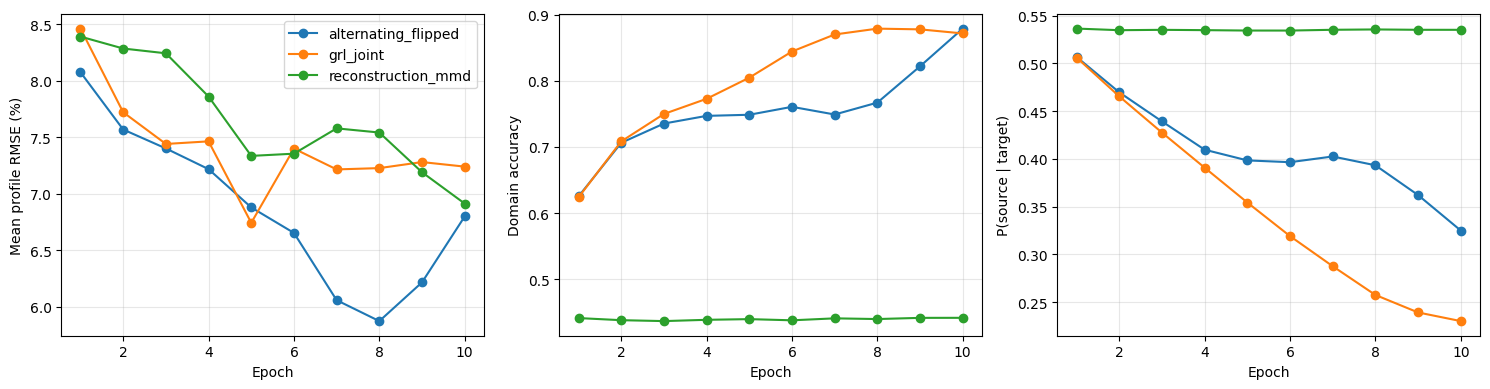

In [ ]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = OUTPUT_ROOT / "formal_paper_ivt/source_artifact.pt"
script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

common = [
    sys.executable,
    str(script),
    "--manifest", str(manifest_path),
    "--data-root", str(DATA_ROOT),
    "--source-artifact", str(source_artifact),
    "--feature-order", "paper_ivt",
    "--seed", "42",
    "--device", "cuda",
    "--transfer-epochs", "10",
    "--patience", "0",
    "--alpha", "10",
    "--beta", "1",
    "--target-bn-mode", "frozen_stats",
    "--resume",
]
experiments = {
    "grl_joint": (
        OUTPUT_ROOT / "diagnostic_frozen_stats_grl_full_loss_10ep",
        None,
    ),
    "reconstruction_mmd": (
        OUTPUT_ROOT / "diagnostic_frozen_stats_reconstruction_mmd_10ep",
        ["--adversarial-weight", "0", "--adversarial-update", "grl_joint"],
    ),
    "alternating_flipped": (
        OUTPUT_ROOT / "diagnostic_frozen_stats_alternating_full_loss_10ep",
        ["--adversarial-weight", "1", "--adversarial-update", "alternating_flipped"],
    ),
}

for name, (output, arguments) in experiments.items():
    if arguments is None:
        assert (output / "results.json").is_file(), f"Missing completed GRL baseline: {output}"
        continue
    output.mkdir(parents=True, exist_ok=True)
    if (output / "results.json").is_file():
        print(f"Using completed result: {name}")
        continue
    command = [*common, "--output", str(output), *arguments]
    print(f"\nRunning: {name}\n{' '.join(command)}")
    subprocess.run(command, cwd=REPO_ROOT, check=True)

epoch_rows = []
profile_rows = []
for name, (output, _) in experiments.items():
    result = json.loads((output / "results.json").read_text())
    assert result["target_bn_mode"] == "frozen_stats"
    for record in result["adaptation_diagnostics"]:
        training = record["training"]
        gradients = training["gradient_l2"]
        bn_drift = training["target_bn_running_stat_drift"]
        epoch_rows.append(
            {
                "experiment": name,
                "epoch": record["epoch"],
                "mean_rmse_percent": training["mean_profile_rmse_percent"],
                "domain_accuracy": training["overall_domain_accuracy"],
                "p_source_given_target": training["mean_p_source_given_target"],
                "adversarial_gradient_l2": gradients["adversarial"],
                "reconstruction_gradient_l2": gradients["reconstruction"],
                "mmd_gradient_l2": gradients["mmd"],
                "target_feature_rms_drift": training["target_feature_rms_drift"],
                "bn_mean_drift": bn_drift["max_running_mean_abs_change"],
                "bn_var_drift": bn_drift["max_running_var_abs_change"],
                "bn_batches_drift": bn_drift["max_num_batches_tracked_change"],
            }
        )
        if record["epoch"] == 10:
            for profile, metrics in training["target_test"].items():
                profile_rows.append({"experiment": name, "profile": profile, **metrics})

epochs = pd.DataFrame(epoch_rows)
profiles = pd.DataFrame(profile_rows)
display(epochs.loc[epochs.epoch.isin([1, 2, 5, 10])])
display(profiles)
assert not epochs[["bn_mean_drift", "bn_var_drift", "bn_batches_drift"]].to_numpy().any()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, group in epochs.groupby("experiment"):
    axes[0].plot(group.epoch, group.mean_rmse_percent, marker="o", label=name)
    axes[1].plot(group.epoch, group.domain_accuracy, marker="o", label=name)
    axes[2].plot(group.epoch, group.p_source_given_target, marker="o", label=name)
axes[0].set_ylabel("Mean profile RMSE (%)")
axes[1].set_ylabel("Domain accuracy")
axes[2].set_ylabel("P(source | target)")
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.grid(True, alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


## Fully-frozen BN alternating diagnostic

This ten-epoch run differs from the preceding alternating experiment only by freezing target-BN affine parameters as well as running statistics. It tests whether late target-feature drift is caused by BN affine updates.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_ivt/source_artifact.pt --feature-order paper_ivt --seed 42 --device cuda --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_fully_frozen_alternating_full_loss_10ep --transfer-epochs 10 --patience 0 --adversarial-weight 1 --alpha 10 --beta 1 --target-bn-mode fully_frozen --adversarial-update alternating_flipped --resume


,target_bn_mode,epoch,mean_rmse_percent,domain_accuracy,p_source_given_target,adversarial_gradient_l2,reconstruction_gradient_l2,mmd_gradient_l2,target_feature_rms_drift,bn_mean_drift,bn_var_drift,bn_batches_drift
0,frozen_stats,1,8.076135,0.625332,0.506642,0.891612,76.229216,8.270257,0.212418,0.0,0.0,0
1,frozen_stats,2,7.569222,0.706263,0.469620,4.041168,382.001206,11.976403,0.319490,0.0,0.0,0
4,frozen_stats,5,6.879605,0.748627,0.398354,17.215349,84.662030,9.167600,0.568629,0.0,0.0,0
7,frozen_stats,8,5.873538,0.766988,0.393247,22.037187,80.158592,4.986731,0.808856,0.0,0.0,0
9,frozen_stats,10,6.799906,0.878791,0.324928,9.947481,37.452535,7.309632,0.913984,0.0,0.0,0
10,fully_frozen,1,9.394974,0.628588,0.503839,0.878214,75.606373,8.220932,0.310106,0.0,0.0,0
11,fully_frozen,2,8.223039,0.719457,0.458525,4.791858,61.437211,14.806563,0.250908,0.0,0.0,0
14,fully_frozen,5,7.198854,0.777816,0.387287,16.279589,80.212142,9.191789,0.532482,0.0,0.0,0
17,fully_frozen,8,6.678071,0.750596,0.394445,17.644186,71.661390,5.523154,0.816734,0.0,0.0,0
19,fully_frozen,10,7.624952,0.850799,0.321412,9.176814,29.249750,7.428716,0.912679,0.0,0.0,0


,target_bn_mode,profile,rmse_percent,mae_percent,n_windows
0,frozen_stats,LA92,5.158950,3.723498,15368
1,frozen_stats,UDDS,6.789664,5.254974,12831
2,frozen_stats,US06,8.888670,7.754727,3635
3,frozen_stats,HWFET,7.922236,6.726194,5961
4,frozen_stats,NN,5.240012,3.748261,13439
5,fully_frozen,LA92,5.859243,4.193862,15368
6,fully_frozen,UDDS,7.634945,5.930638,12831
7,fully_frozen,US06,9.495485,8.228287,3635
8,fully_frozen,HWFET,9.242591,7.880144,5961
9,fully_frozen,NN,5.892498,4.201434,13439


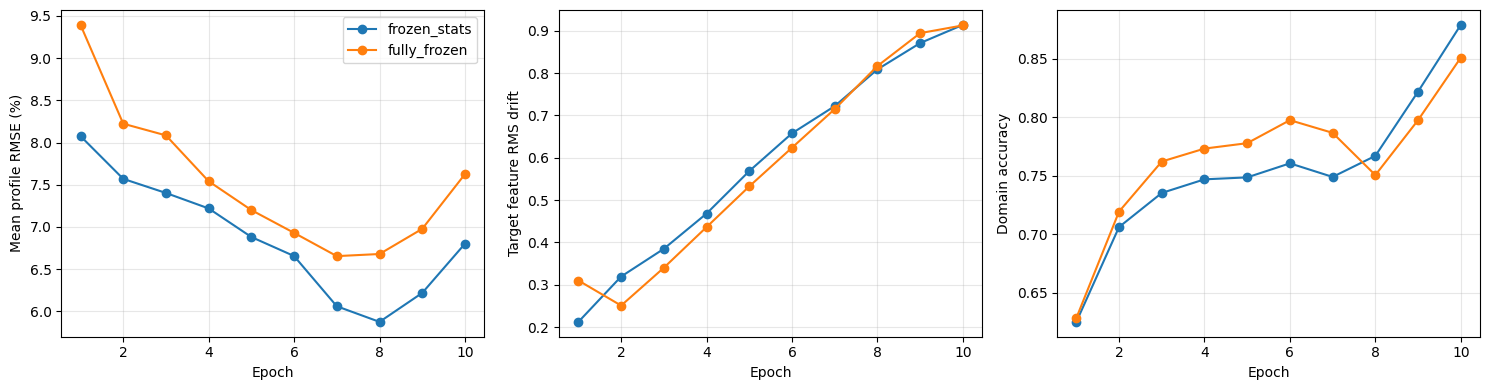

In [22]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

source_artifact = OUTPUT_ROOT / "formal_paper_ivt/source_artifact.pt"
script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
manifest_path = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
frozen_stats_output = OUTPUT_ROOT / "diagnostic_frozen_stats_alternating_full_loss_10ep"
fully_frozen_output = OUTPUT_ROOT / "diagnostic_fully_frozen_alternating_full_loss_10ep"

assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"
assert (frozen_stats_output / "results.json").is_file(), "Missing frozen-stats baseline"
fully_frozen_output.mkdir(parents=True, exist_ok=True)
if not (fully_frozen_output / "results.json").is_file():
    command = [
        sys.executable,
        str(script),
        "--manifest", str(manifest_path),
        "--data-root", str(DATA_ROOT),
        "--source-artifact", str(source_artifact),
        "--feature-order", "paper_ivt",
        "--seed", "42",
        "--device", "cuda",
        "--output", str(fully_frozen_output),
        "--transfer-epochs", "10",
        "--patience", "0",
        "--adversarial-weight", "1",
        "--alpha", "10",
        "--beta", "1",
        "--target-bn-mode", "fully_frozen",
        "--adversarial-update", "alternating_flipped",
        "--resume",
    ]
    print(" ".join(command))
    subprocess.run(command, cwd=REPO_ROOT, check=True)
else:
    print(f"Using completed result: {fully_frozen_output}")

experiments = {
    "frozen_stats": frozen_stats_output,
    "fully_frozen": fully_frozen_output,
}
epoch_rows = []
profile_rows = []
for name, output in experiments.items():
    result = json.loads((output / "results.json").read_text())
    assert result["target_bn_mode"] == name
    assert result["adversarial_update"] == "alternating_flipped"
    for record in result["adaptation_diagnostics"]:
        training = record["training"]
        gradients = training["gradient_l2"]
        bn_drift = training["target_bn_running_stat_drift"]
        epoch_rows.append(
            {
                "target_bn_mode": name,
                "epoch": record["epoch"],
                "mean_rmse_percent": training["mean_profile_rmse_percent"],
                "domain_accuracy": training["overall_domain_accuracy"],
                "p_source_given_target": training["mean_p_source_given_target"],
                "adversarial_gradient_l2": gradients["adversarial"],
                "reconstruction_gradient_l2": gradients["reconstruction"],
                "mmd_gradient_l2": gradients["mmd"],
                "target_feature_rms_drift": training["target_feature_rms_drift"],
                "bn_mean_drift": bn_drift["max_running_mean_abs_change"],
                "bn_var_drift": bn_drift["max_running_var_abs_change"],
                "bn_batches_drift": bn_drift["max_num_batches_tracked_change"],
            }
        )
        if record["epoch"] == 10:
            for profile, metrics in training["target_test"].items():
                profile_rows.append({"target_bn_mode": name, "profile": profile, **metrics})

epochs = pd.DataFrame(epoch_rows)
profiles = pd.DataFrame(profile_rows)
display(epochs.loc[epochs.epoch.isin([1, 2, 5, 8, 10])])
display(profiles)
assert not epochs[["bn_mean_drift", "bn_var_drift", "bn_batches_drift"]].to_numpy().any()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, group in epochs.groupby("target_bn_mode"):
    axes[0].plot(group.epoch, group.mean_rmse_percent, marker="o", label=name)
    axes[1].plot(group.epoch, group.target_feature_rms_drift, marker="o", label=name)
    axes[2].plot(group.epoch, group.domain_accuracy, marker="o", label=name)
axes[0].set_ylabel("Mean profile RMSE (%)")
axes[1].set_ylabel("Target feature RMS drift")
axes[2].set_ylabel("Domain accuracy")
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.grid(True, alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


## Interpretation

- Smoke metrics only prove that the complete real-data path runs; they are not comparable with the paper.
- Formal results are comparable only with the reconstruction assumptions recorded in `results.json`.
- `source_last.pt` and `adapt_last.pt` support resuming interrupted formal runs.
- Adaptation diagnostics use target labels only after each epoch and never feed them into training or model selection.